# 04. 하루 혼잡도 곡선으로 역 군집화

03에서 혼잡도의 남은 변동은 '역·방향마다 다른 하루 곡선'에서 나온다는 것을 확인했다.
여기서는 평일 역·방향 543개의 **하루 곡선 모양**으로 군집을 나눈다.

**설계**
- 입력: 06:00~23:30 30분 단위 혼잡도 36개 값. 이 구간에서는 모든 역·방향에 값이 있다.
- **모양만 비교**하려고 각 곡선을 자기 평균으로 나눈다(1.0 = 그 역·방향의 하루 평균). 혼잡도 수준은 군집을 나눈 뒤 따로 본다.
- 환승 여부, 노선 같은 속성은 군집 입력에 넣지 않는다. 입력에 넣으면 그 속성대로 나뉘는 자명한 결과가 나오기 때문이다. 속성은 군집을 해석할 때만 쓴다.
- K-Means, k는 실루엣 점수와 시드를 바꿨을 때의 안정성(ARI), 해석 가능성을 함께 보고 정한다.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

from subway.load import load_congestion
from subway.clean import clean_congestion
from subway.transfer import load_station_master, transfer_table

sns.set_theme(style="whitegrid", font="Malgun Gothic", rc={"axes.unicode_minus": False})
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, FIG = ROOT / "data" / "raw", ROOT / "reports" / "figures"

df = clean_congestion(load_congestion(RAW / "서울교통공사_지하철혼잡도정보_20260930.csv"))
transfers = transfer_table(load_station_master(RAW / "서울시 역사마스터 정보.csv"))

KEY = ["line", "station_code", "station", "direction"]
profiles = df[df.day_type == "평일"].pivot_table(index=KEY, columns="hour", values="congestion").loc[:, 6.0:23.5]
assert profiles.notna().all().all()
shape = profiles.div(profiles.mean(axis=1), axis=0)
print(f"역·방향 {len(profiles)}개 × 시각 {profiles.shape[1]}개")

역·방향 543개 × 시각 36개


## 1. k 정하기

In [2]:
rows = []
for k in range(2, 9):
    base = KMeans(k, n_init=50, random_state=0).fit(shape)
    ari = np.mean([adjusted_rand_score(base.labels_, KMeans(k, n_init=50, random_state=s).fit_predict(shape)) for s in range(1, 6)])
    rows.append({"k": k, "실루엣": silhouette_score(shape, base.labels_), "시드 안정성(ARI)": ari,
                 "군집 크기": sorted(np.bincount(base.labels_).tolist(), reverse=True)})
scan = pd.DataFrame(rows).set_index("k")
scan.round(3)

,실루엣,시드 안정성(ARI),군집 크기
k,,,
2,0.510,1.000,"[298, 245]"
3,0.367,1.000,"[229, 166, 148]"
4,0.272,1.000,"[151, 138, 134, 120]"
5,0.217,0.986,"[142, 113, 106, 94, 88]"
6,0.206,0.985,"[130, 112, 89, 85, 72, 55]"
7,0.185,0.985,"[130, 84, 79, 73, 73, 55, 49]"
8,0.187,0.926,"[130, 86, 73, 73, 66, 53, 50, 12]"


- 실루엣 점수는 k=2가 가장 높고 k가 커질수록 줄어든다. k=2는 '아침에 붐비는 곡선 vs 저녁에 붐비는 곡선'으로만 나뉜다.
- **k=3**은 여기에 '아침·저녁 모두 붐비는 곡선'이 따로 분리된다. 실루엣은 두 번째로 높고, 시드를 바꿔도 결과가 거의 같다(ARI ≈ 0.99).
- k=4부터는 세 번째 군집이 '아침 쪽'과 '저녁 쪽'으로 쪼개질 뿐이라 새로운 유형이 생기지 않는다. 시드 안정성은 k=7까지 높지만, 실루엣 점수가 계속 떨어져 군집 경계가 흐려진다.
- 그래서 **k=3**을 쓴다.

In [3]:
km = KMeans(3, n_init=50, random_state=0).fit(shape)
centers = pd.DataFrame(km.cluster_centers_, columns=shape.columns)
am_type, pm_type = centers[8.0].idxmax(), centers[18.0].idxmax()
names = {am_type: "아침형", pm_type: "저녁형"}
names[({0, 1, 2} - {am_type, pm_type}).pop()] = "양봉형"
ORDER = ["아침형", "저녁형", "양봉형"]
COLORS = {"아침형": "#4c72b0", "저녁형": "#c44e52", "양봉형": "#8172b3"}

labels = pd.Series(km.labels_, index=profiles.index).map(names).rename("유형")
info = profiles.mean(axis=1).rename("하루 평균").to_frame().join(labels)
info["08시"], info["18시"] = profiles[8.0], profiles[18.0]
info = info.reset_index().merge(transfers[["line", "station", "is_transfer", "lat", "lon"]], on=["line", "station"])
summary = info.groupby("유형").agg(**{"역·방향 수": ("하루 평균", "size"), "하루 평균": ("하루 평균", "mean"),
                                    "08시 평균": ("08시", "mean"), "18시 평균": ("18시", "mean"), "환승역 비율": ("is_transfer", "mean")})
summary.loc[ORDER].round(2)

,역·방향 수,하루 평균,08시 평균,18시 평균,환승역 비율
유형,,,,,
아침형,166,33.54,89.16,32.83,0.31
저녁형,229,35.94,36.02,81.85,0.39
양봉형,148,37.31,69.40,61.08,0.47


## 2. 유형별 하루 곡선

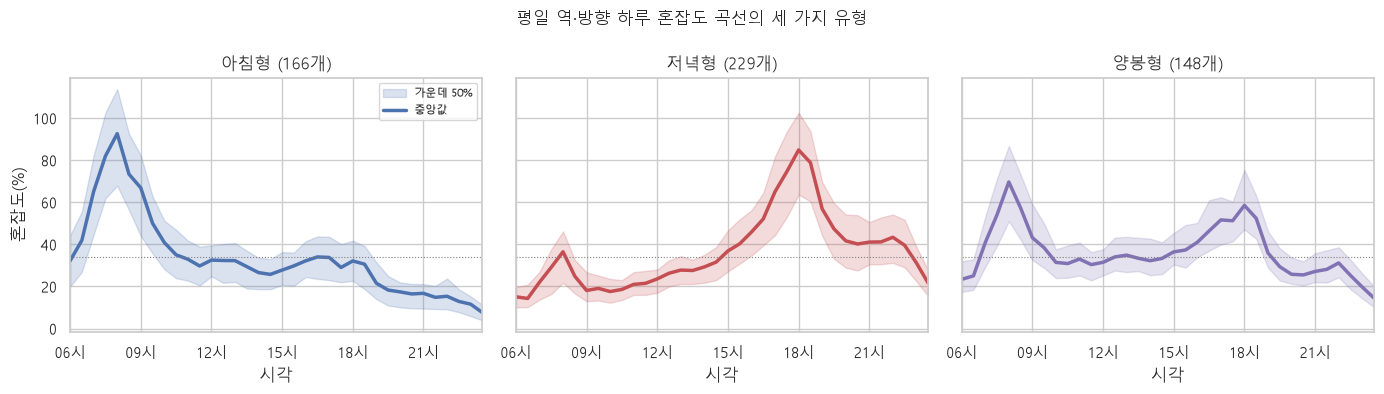

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
hours = profiles.columns
for ax, name in zip(axes, ORDER):
    members = profiles[labels == name]
    q25, q50, q75 = members.quantile(0.25), members.median(), members.quantile(0.75)
    ax.fill_between(hours, q25, q75, color=COLORS[name], alpha=0.2, label="가운데 50%")
    ax.plot(hours, q50, color=COLORS[name], lw=2.5, label="중앙값")
    ax.axhline(34, color="gray", lw=0.8, ls=":")
    ax.set(title=f"{name} ({len(members)}개)", xlabel="시각", xlim=(6, 23.5))
    ax.set_xticks(range(6, 24, 3)); ax.set_xticklabels([f"{h:02d}시" for h in range(6, 24, 3)])
axes[0].set_ylabel("혼잡도(%)"); axes[0].legend(fontsize=8, loc="upper right")
fig.suptitle("평일 역·방향 하루 혼잡도 곡선의 세 가지 유형", fontsize=12)
plt.tight_layout(); plt.savefig(FIG / "07_cluster_profiles.png", dpi=150); plt.show()

In [5]:
for name in ORDER:
    top = info[info.유형 == name].sort_values("하루 평균", ascending=False).head(6)
    print(f"{name}: " + ", ".join(f"{r['line']}호선 {r['station']} {r['direction']}({r['하루 평균']:.0f}%)" for _, r in top.iterrows()))

아침형: 2호선 서초 외선(56%), 2호선 교대 외선(56%), 4호선 동대문 하선(56%), 2호선 사당 외선(55%), 7호선 어린이대공원 하선(55%), 2호선 방배 외선(55%)
저녁형: 2호선 방배 내선(61%), 2호선 교대 내선(61%), 2호선 서초 내선(61%), 5호선 강동 하선(59%), 2호선 강남 내선(59%), 8호선 잠실 상선(58%)
양봉형: 8호선 송파 상선(64%), 8호선 석촌 상선(62%), 8호선 석촌 하선(62%), 8호선 가락시장 상선(61%), 8호선 송파 하선(59%), 8호선 잠실 하선(59%)


- **아침형**: 08시에 하루 평균의 약 2.7배까지 치솟고 저녁엔 한산하다. 주거지에서 업무지구로 들어가는 방향이다(2호선 사당~서초 외선, 7호선 어린이대공원·군자 하선, 8호선 몽촌토성 하선 등).
- **저녁형**: 아침엔 평범하다가 18시에 하루 평균의 2.3배가 된다. 업무지구에서 주거지로 나가는 방향이다.
- **양봉형**: 아침·저녁 모두 붐비고 낮에도 덜 빠진다. 08시와 18시 평균이 모두 60%를 넘는다. 환승역 비율(47%)도 세 유형 중 가장 높다.

## 3. 한 역의 두 방향은 어떤 조합인가

In [6]:
combo = (info.groupby(["line", "station_code", "station"]).유형
         .apply(lambda s: " + ".join(sorted(s, key=ORDER.index)) if len(s) == 2 else f"{s.iloc[0]} (한 방향만)")
         .rename("조합"))
combo_count = combo.value_counts()
print(combo_count.to_string())
print(f"\n'아침형 + 저녁형' 비율: {combo_count.get('아침형 + 저녁형', 0) / len(combo):.0%}")

조합
아침형 + 저녁형      151
저녁형 + 양봉형       72
양봉형 + 양봉형       33
아침형 (한 방향만)     10
저녁형 (한 방향만)      6
아침형 + 양봉형        5
양봉형 (한 방향만)      5

'아침형 + 저녁형' 비율: 54%


**1~8호선 (노선, 역) 282개 중 절반이 넘는 151개는 한쪽 방향이 아침형, 반대쪽이 저녁형이다.**
아침에 도심으로 들어간 사람들이 저녁에 같은 길로 돌아오기 때문에, 한 역의 두 방향은 서로의 거울상이 된다.
그래서 '이 역은 붐빈다/한산하다'고 말할 수 없고, 반드시 **방향과 시각을 함께** 봐야 한다.

## 4. 지도로 보기

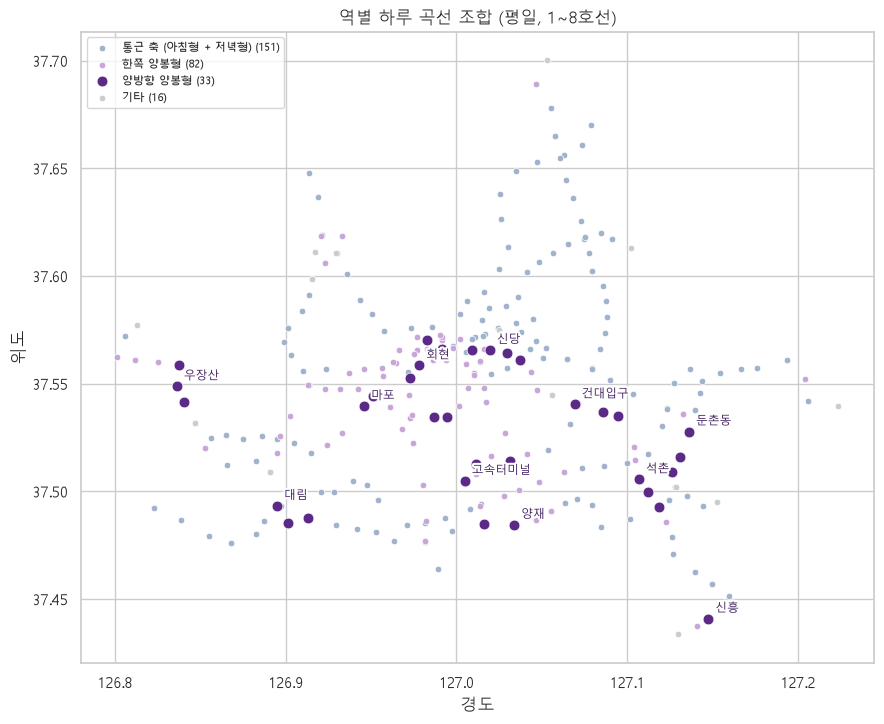

양방향 양봉형: 1호선 종각, 2호선 강변, 2호선 건대입구, 2호선 구로디지털단지, 2호선 구의, 2호선 대림, 2호선 동대문역사문화공원, 2호선 상왕십리, 2호선 신당, 2호선 신대방, 2호선 왕십리, 2호선 을지로3가, 3호선 고속터미널, 3호선 남부터미널, 3호선 양재, 3호선 잠원, 4호선 서울역, 4호선 회현, 5호선 공덕, 5호선 둔촌동, 5호선 마포, 5호선 발산, 5호선 방이, 5호선 올림픽공원, 5호선 우장산, 5호선 화곡, 6호선 녹사평, 6호선 이태원, 7호선 학동, 8호선 가락시장, 8호선 석촌, 8호선 송파, 8호선 신흥


In [7]:
station_type = combo.reset_index().merge(transfers[["line", "station", "lat", "lon"]], on=["line", "station"])
station_type["지도 유형"] = station_type.조합.map(lambda s: "양방향 양봉형" if s == "양봉형 + 양봉형"
                                             else "한쪽 양봉형" if "양봉형" in s
                                             else "통근 축 (아침형 + 저녁형)" if s == "아침형 + 저녁형" else "기타")
map_colors = {"통근 축 (아침형 + 저녁형)": "#9fb4cc", "한쪽 양봉형": "#c9a6d8", "양방향 양봉형": "#5b2a86", "기타": "#cccccc"}

fig, ax = plt.subplots(figsize=(9, 7.5))
for t, color in map_colors.items():
    s = station_type[station_type["지도 유형"] == t]
    ax.scatter(s.lon, s.lat, s=60 if t == "양방향 양봉형" else 22, color=color, label=f"{t} ({len(s)})",
               edgecolor="white", lw=0.5, zorder=3 if t == "양방향 양봉형" else 2)
import matplotlib.patheffects as pe
labeled = []
for r in station_type[station_type["지도 유형"] == "양방향 양봉형"].drop_duplicates("station").sort_values("lon").itertuples():
    if all(np.hypot(r.lon - x, r.lat - y) > 0.035 for x, y in labeled):  # 가까운 역끼리 이름이 겹치지 않게 하나만 표시
        ax.annotate(r.station, (r.lon, r.lat), xytext=(5, 5), textcoords="offset points", fontsize=8.5, color="#3b1a5a",
                    path_effects=[pe.withStroke(linewidth=3, foreground="white")], zorder=4)
        labeled.append((r.lon, r.lat))
ax.set_aspect(1 / np.cos(np.radians(37.55)))
ax.set(xlabel="경도", ylabel="위도", title="역별 하루 곡선 조합 (평일, 1~8호선)")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "08_cluster_map.png", dpi=150); plt.show()

both = station_type[station_type["지도 유형"] == "양방향 양봉형"].sort_values(["line", "station"])
print("양방향 양봉형:", ", ".join(f"{r.line}호선 {r.station}" for r in both.itertuples()))

양방향 양봉형 역은 한곳에 몰려 있지 않고 여러 거점에 흩어져 있다.
- 도심: 종각·을지로3가·동대문역사문화공원·신당·서울역·회현, 왕십리·상왕십리
- 도심 서쪽·남쪽: 마포·공덕, 이태원·녹사평
- 2호선 동쪽: 건대입구~강변, 서남쪽: 구로디지털단지·대림·신대방
- 강남·서초(3호선 잠원~양재, 7호선 학동), 송파 5·8호선(둔촌동~가락시장), 강서 5호선(발산~화곡)

공통점은 **사람이 들어오는 곳이면서 동시에 나가는 곳**이라는 점이다. 업무지구와 주거지가 섞여 있거나 노선 중간의 거점이라 어느 방향으로든 통근 흐름이 지나간다.
나머지 대부분의 역은 '통근 축'으로, 시간과 방향만 잘 고르면 혼잡을 크게 피할 수 있다.

## 정리

| 유형 | 특징 | 대학생 이동 팁 |
|---|---|---|
| 아침형 | 08시 피크가 하루 평균의 약 2.7배, 저녁엔 한산 | 07:30 이전에 타면 효과가 크다 |
| 저녁형 | 18시 피크가 하루 평균의 약 2.3배, 아침엔 평범 | 17시 이전 하교가 유리하다 |
| 양봉형 | 아침·저녁 모두 붐비고 낮에도 덜 빠짐 | 등교·하교 모두 피크를 피해야 한다. 낮 시간도 30~40%대라 완전히 한산하지는 않다 |

- 역의 절반 이상이 '한 방향은 아침형, 반대 방향은 저녁형'인 통근 축 구조다.
- 이 유형 정보는 웹앱에서 '이 구간은 시간을 바꾸면 얼마나 나아지나'를 설명하는 데 쓴다.

**한계**
- 곡선을 자기 평균으로 나눠 모양만 비교했다. 같은 아침형이라도 피크가 60%인 곳과 140%인 곳이 섞여 있다.
- 평일만 분석했다. 주말은 피크 구조가 달라 따로 군집화해야 한다.

다음 단계: 역간 소요시간으로 노선 그래프를 만들고, 출발역→도착역 경로의 시각별 혼잡도를 계산한다.